# Настройка гиперпараметров классификатора методом NSGA-II

**Лабораторная работа № 3, вариант 10, трек A.** Подбор гиперпараметров модели классификации по трём конкурирующим критериям:

1. **максимум качества** классификации (доля верных ответов на тестовой выборке);
2. **минимум времени обучения** (вычислительной стоимости обучения);
3. **минимум числа параметров** модели.

Реализован самостоятельный алгоритм NSGA-II: недоминируемая сортировка, расстояние до скопления (crowding distance), турнир по рангу и скоплению, SBX-кроссовер и полиномиальная мутация. Готовые реализации многокритериальной оптимизации не используются. Модель классификатора также реализована вручную на `numpy` (`tuning_nsga2.py`).

## Постановка задачи

Генотип — вектор гиперпараметров $x = (x_1, \ldots, x_5) \in D$, область $D$ задаётся границами генов (таблица ниже). Каждому генотипу соответствует обученная модель и три значения критериев, все критерии минимизируются:

$$f_1(x) = \text{ошибка на тесте}, \qquad f_2(x) = \text{стоимость обучения}, \qquad f_3(x) = \text{число параметров}.$$

Решение $x$ **доминирует** $y$ ($x \prec y$), если

$$\forall k\; f_k(x) \le f_k(y) \quad \text{и} \quad \exists k\; f_k(x) < f_k(y).$$

**Фронт Парето** — множество взаимно недоминируемых решений. В отличие от ЛР1–2, целью является не одна лучшая точка, а набор компромиссов: например, маленькая быстрая модель с умеренной ошибкой или точная, но дорогая.

Сравнение наборов решений проводится по **гиперобъёму** (hypervolume) — мере области, доминируемой фронтом относительно опорной точки $r$ (все критерии минимизируются):

$$HV(F) = \Lambda\bigl(\{v \le r : \exists x \in F,\; f(x) \prec v\}\bigr),$$

чем больше гиперобъём, тем лучше фронт приближает истинное множество Парето.

In [1]:
%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import tuning_nsga2 as tn

pd.set_option("display.float_format", lambda v: f"{v:.4g}")
data = tn.generate_data()
print(f"Обучающая выборка: {data.x_train.shape}, тестовая: {data.x_test.shape}, классов: {data.n_classes}")
print(f"Признаков: {data.n_features} (стандартизованы), data_seed = {data.data_seed}")
pd.Series(data.y_train).value_counts().sort_index().rename("Число объектов").to_frame().T

Обучающая выборка: (560, 10), тестовая: (240, 10), классов: 3
Признаков: 10 (стандартизованы), data_seed = 202610


,0,1,2
Число объектов,190,187,183


## Модель классификатора

Модель — нейронная сеть с одним скрытым слоем (при $x_1 = 0$ вырождается в линейную логистическую регрессию):

$$h = \tanh(W_1 \tilde{x} + b_1), \qquad \hat{p} = \mathrm{softmax}(W_2 h + b_2),$$

где $\tilde{x}$ — стандартизованный вектор признаков. Обучение — мини-батчевый градиентный спуск по кросс-энтропии с L2-регуляризацией; все градиенты выписаны и реализованы вручную. Порядок перемешивания батчей фиксирован генератором с `data_seed`, поэтому результат оценки полностью детерминирован при заданном генотипе.

**Число параметров** (третий критерий):

$$P(x) = \begin{cases} (d+1)C, & x_1 = 0, \\ (d+1)x_1 + (x_1+1)C, & x_1 > 0, \end{cases}$$

где $d = 10$ — число признаков, $C = 3$ — число классов.

**Стоимость обучения** (второй критерий) — детерминированный прокси времени, пропорциональный числу скалярных обновлений весов:

$$f_2(x) = \text{epochs} \cdot \left\lceil \frac{n_{\text{train}}}{\text{batch}} \right\rceil \cdot P(x).$$

Фактическое время обучения дополнительно измеряется и сохраняется в результатах; оно сильно коррелирует с $f_2$, но шумно, поэтому в качестве критерия используется стабильный прокси.

## Генотип: гены и границы

| Ген | Гиперпараметр | Тип | Диапазон |
|---|---|---|---|
| $x_1$ | число нейронов скрытого слоя | целое | $0 \ldots 16$ |
| $x_2$ | $\log_{10}$ скорости обучения | вещественное | $[-3, -1]$ |
| $x_3$ | число эпох | целое | $5 \ldots 150$ |
| $x_4$ | коэффициент L2 | вещественное | $[0, 0.05]$ |
| $x_5$ | $\log_2$ размера батча | целое | $\{5,6,7\}$ ($32/64/128$) |

Ген $x_2$ кодируется логарифмом, чтобы скорости обучения порядка $10^{-3}$ и $10^{-1}$ были равнодоступны для операторов вариации.

In [2]:
genome = np.array([8.0, -1.5, 50.0, 0.001, 5.0])
params = tn.decode(genome)
test_error, cost, count, seconds = tn.train_and_eval(params, data)
print(f"genome   = {genome.tolist()}")
print(f"decode   = {params}")
print(f"f1 (ошибка на тесте)       = {test_error:.3f}")
print(f"f2 (стоимость обучения)    = {cost:.0f}")
print(f"f3 (число параметров)      = {count}")
print(f"фактическое время обучения = {seconds*1000:.1f} мс")
print(f"опорная точка гиперобъёма  = {tn.reference_point(data)}")

genome   = [8.0, -1.5, 50.0, 0.001, 5.0]
decode   = {'hidden': 8, 'lr': 0.03162277660168379, 'epochs': 50, 'l2': 0.001, 'batch_size': 32}
f1 (ошибка на тесте)       = 0.146
f2 (стоимость обучения)    = 103500
f3 (число параметров)      = 115
фактическое время обучения = 19.4 мс
опорная точка гиперобъёма  = (0.5, np.float64(674190.0), 249.70000000000002)


## Операторы NSGA-II

**Недоминируемая сортировка** раскладывает популяцию на фронты $F_1, F_2, \ldots$, где $F_1$ — взаимно недоминируемые решения, а каждое решение из $F_{i+1}$ доминируется хотя бы одним решением из $F_i$. Ранг особи — номер её фронта.

**Расстояние до скопления** для фронта $F$ по критерию $k$ (после сортировки по $f_k$):

$$d_i^{(k)} = \frac{f_k(x_{i+1}) - f_k(x_{i-1})}{f_k^{\max} - f_k^{\min}}, \qquad d_1 = d_{|F|} = +\infty, \qquad d(x) = \sum_k d_i^{(k)}.$$

Крайние по каждому критерию решения получают бесконечное расстояние и никогда не вытесняются — это поддерживает разнообразие фронта.

**Турнирная селекция:** из двух случайных особей выбирается та, у которой меньше ранг; при равных рангах — большее расстояние до скопления.

**Вариация:** SBX-кроссовер (аналогичен ЛР1, $\eta = 15$) и полиномиальная мутация ($\eta = 20$) покоординатно с вероятностью `mutation_prob`; целочисленные гены округляются и прижимаются к границам области.

**Элитизм:** родители и потомки объединяются, из объединённой популяции отбираются `population_size` лучших по правилу (ранг, убывание расстояния до скопления).

Остановка — по числу оцениваний модели (бюджет), начальная популяция входит в бюджет, как в ЛР1–2.

In [3]:
config = tn.GAConfig(seed=42, method="nsga2")
result = tn.run_method(data, config)
print(f"Оценено моделей: {result['n_evals']}, фронт Парето: {result['front_size']} решений")
print(f"Гиперобъём фронта: {result['hypervolume']:.4g}, время запуска: {result['elapsed_seconds']:.1f} с")
print(f"Лучшая ошибка на фронте: {min(o[0] for o in result['front_objectives']):.3f}")

Оценено моделей: 1000, фронт Парето: 72 решений
Гиперобъём фронта: 8.568e+07, время запуска: 6.1 с
Лучшая ошибка на фронте: 0.121


## Фронт Парето одного запуска

Ниже — две проекции трёхкритериального фронта: «ошибка ↔ стоимость» и «ошибка ↔ число параметров». Точки несопоставимы по Парето: любое улучшение одного критерия ухудшает другой.

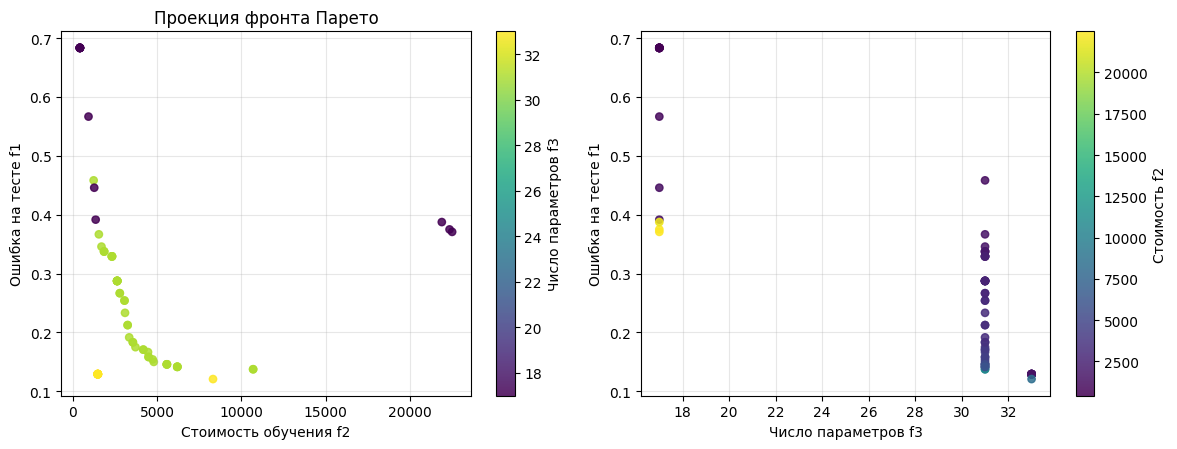

In [4]:
front = np.array(result["front_objectives"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, (j, ylabel) in zip(axes, [(1, "Стоимость обучения f2"), (2, "Число параметров f3")]):
    sc = ax.scatter(front[:, j], front[:, 0], c=front[:, 3 - j], cmap="viridis", s=28, alpha=0.85)
    ax.set_xlabel(ylabel)
    ax.set_ylabel("Ошибка на тесте f1")
    ax.grid(alpha=0.3)
    fig.colorbar(sc, ax=ax, label="Число параметров f3" if j == 1 else "Стоимость f2")
axes[0].set_title("Проекция фронта Парето")
fig.tight_layout()
plt.show()

## Три характерных решения

Из фронта выбираются три компромисса: **«быстрое»** (минимум $f_2$), **«точное»** (минимум $f_1$) и **«сбалансированное»** (ближайшее к утопической точке в нормированных координатах). Для каждого решения дополнительно приводится фактическое время обучения.

In [5]:
ref = np.array(tn.reference_point(data))
norm = front / ref
ideal = norm.min(axis=0)
knee = int(np.argmin(np.linalg.norm(norm - ideal, axis=1)))
fast = int(np.argmin(front[:, 1]))
accurate = int(np.argmin(front[:, 0]))

rows = []
for label, i in [("быстрое", fast), ("сбалансированное", knee), ("точное", accurate)]:
    params = tn.decode(np.array(result["front_genomes"][i]))
    *_, seconds = tn.train_and_eval(params, data)
    rows.append({
        "Решение": label,
        "Нейронов": params["hidden"],
        "Скорость обучения": f"{params['lr']:.2g}",
        "Эпох": params["epochs"],
        "L2": params["l2"],
        "Батч": params["batch_size"],
        "Ошибка f1": round(front[i, 0], 4),
        "Стоимость f2": f"{front[i, 1]:.3g}",
        "Параметров f3": int(front[i, 2]),
        "Время обучения, мс": round(seconds * 1000, 1),
    })
pd.DataFrame(rows)

,Решение,Нейронов,Скорость обучения,Эпох,L2,Батч,Ошибка f1,Стоимость f2,Параметров f3,"Время обучения, мс"
0,быстрое,1,0.095,5,0.02956,128,0.6833,425,17,0.9
1,сбалансированное,0,0.0026,28,0.008803,64,0.1208,8.32e+03,33,2.9
2,точное,0,0.0026,28,0.008803,64,0.1208,8.32e+03,33,2.9


Одиночный запуск демонстрирует работоспособность алгоритма и вид компромиссов, но не является доказательством эффективности: серия из 20 независимых запусков, сравнение с взвешенной суммой критериев и со случайным поиском приведены в `02_experiments.ipynb`.